In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

data = load_breast_cancer()

X = data.data
y = data.target

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("Train:", X_train.shape)
print("Test:", X_test.shape)


Train: (455, 30)
Test: (114, 30)


In [4]:

class GaussianNaiveBayes:

    def fit(self, X, y):
        self.classes = np.unique(y)

        self.means = {}
        self.variances = {}
        self.priors = {}

        for c in self.classes:
            X_c = X[y == c]

            self.means[c] = np.mean(X_c, axis=0)
            self.variances[c] = np.var(
                X_c, axis=0
            ) + 1e-9

            self.priors[c] = len(X_c) / len(X)

        return self

    def _log_likelihood(self, X, c):
        mean = self.means[c]
        var = self.variances[c]

        return -0.5 * np.sum(
            np.log(2 * np.pi * var)
            + ((X - mean) ** 2) / var,
            axis=1
        )

    def predict(self, X):
        scores = []

        for c in self.classes:
            log_prior = np.log(self.priors[c])

            log_likelihood = self._log_likelihood(
                X, c
            )

            scores.append(log_prior + log_likelihood)

        scores = np.column_stack(scores)

        return self.classes[np.argmax(scores, axis=1)]

In [5]:
import numpy as np
import matplotlib.pyplot as plt


class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.1, epochs=3000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.w = None
        self.b = 0.0
        self.losses = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.losses = []

        for epoch in range(self.epochs):
            # Forward pass
            z = X @ self.w + self.b
            probabilities = self.sigmoid(z)

            # Binary cross-entropy
            eps = 1e-15
            p = np.clip(probabilities, eps, 1 - eps)

            loss = -np.mean(
                y * np.log(p)
                + (1 - y) * np.log(1 - p)
            )

            self.losses.append(loss)

            # Gradients
            error = probabilities - y
            dw = (X.T @ error) / n_samples
            db = np.mean(error)

            # Parameter updates
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

        return self

    def predict_proba(self, X):
        return self.sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)
        

In [6]:
import numpy as np
import matplotlib.pyplot as plt


class LinearSVMScratch:

    def __init__(self, learning_rate=0.01, epochs=3000, C=1.0):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.C = C
        self.w = None
        self.b = 0.0
        self.losses = []

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Convert labels: 0 -> -1, 1 -> +1
        y_signed = np.where(y == 0, -1.0, 1.0)

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.losses = []

        for epoch in range(self.epochs):
            # Calculate scores and margins
            scores = X @ self.w + self.b
            margins = y_signed * scores

            # Hinge loss
            hinge_losses = np.maximum(0, 1 - margins)

            # Objective: regularization + average hinge loss
            loss = (
                0.5 * np.dot(self.w, self.w)
                + self.C * np.mean(hinge_losses)
            )
            self.losses.append(loss)

            # Samples violating the margin
            active = margins < 1

            # Gradients
            dw = self.w.copy()
            db = 0.0

            if np.any(active):
                dw -= (
                    self.C / n_samples
                ) * (X[active].T @ y_signed[active])

                db = -self.C * np.mean(y_signed[active])

            # Update parameters
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        scores = self.decision_function(X)
        return (scores >= 0).astype(int)

In [7]:
# 1. Gaussian Naive Bayes
nb_model = GaussianNaiveBayes()
nb_model.fit(X_train, y_train)
nb_predictions = nb_model.predict(X_test)

# 2. Logistic Regression
lr_model = LogisticRegressionScratch(
    learning_rate=0.1,
    epochs=3000
)
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

# 3. Linear SVM
svm_model = LinearSVMScratch(
    learning_rate=0.01,
    epochs=3000,
    C=1.0
)
svm_model.fit(X_train, y_train)
svm_predictions = svm_model.predict(X_test)

In [8]:
# calculate evaluation metrics

predictions = {
    "Naive Bayes": nb_predictions,
    "Logistic Regression": lr_predictions,
    "Linear SVM": svm_predictions
}

results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Malignant Precision": precision_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),
        "Malignant Recall": recall_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),
        "Malignant F1": f1_score(
            y_test, y_pred, pos_label=0, zero_division=0
        )
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Malignant Precision,Malignant Recall,Malignant F1
Model,,,,
Naive Bayes,0.9298,0.9048,0.9048,0.9048
Logistic Regression,0.9737,0.9535,0.9762,0.9647
Linear SVM,0.9561,1.0000,0.8810,0.9367


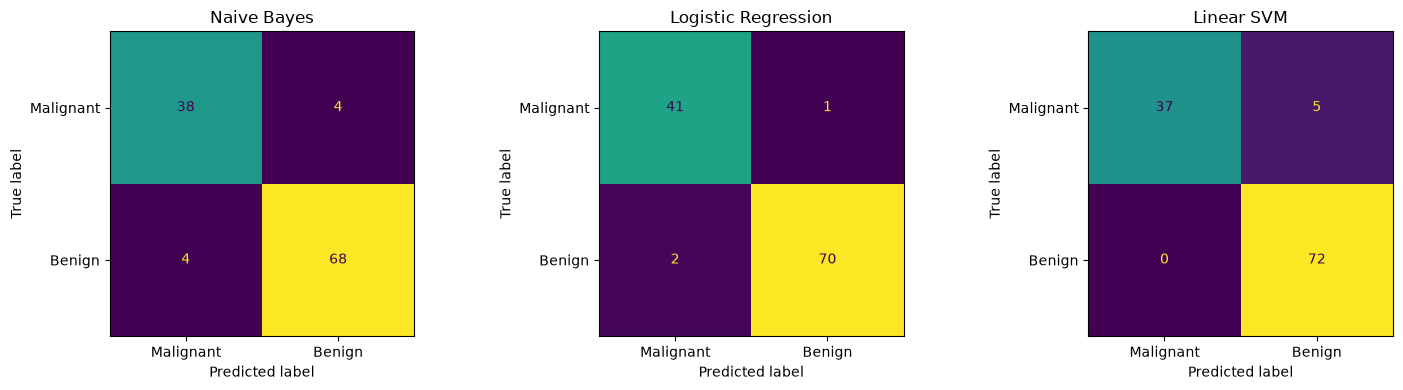

In [9]:
# visualize confusion matrices

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Malignant", "Benign"]
    )

    display.plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [10]:
# compare individual predictions 
comparison_df = pd.DataFrame({
    "Actual": y_test,
    "Naive Bayes": nb_predictions,
    "Logistic Regression": lr_predictions,
    "Linear SVM": svm_predictions
})

comparison_df["All Agree"] = (
    (comparison_df["Naive Bayes"] ==
     comparison_df["Logistic Regression"])
    &
    (comparison_df["Logistic Regression"] ==
     comparison_df["Linear SVM"])
)

display(comparison_df.head(20))

print(
    "Samples where models disagree:",
    (~comparison_df["All Agree"]).sum()
)

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [11]:
for name, y_pred in predictions.items():
    print(f"\n{'=' * 50}")
    print(name)
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Malignant", "Benign"],
        zero_division=0
    ))


Naive Bayes
              precision    recall  f1-score   support

   Malignant       0.90      0.90      0.90        42
      Benign       0.94      0.94      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114


Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.95      0.98      0.96        42
      Benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


Linear SVM
              precision    recall  f1-score   support

   Malignant       1.00      0.88      0.94        42
      Benign       0.94      1.00      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.94      0.95       114
weighted avg       0.96     